# 00 · Data inventory (Stage 0)

**Gate:** file list + checksums (build spec §9).

This notebook answers three questions before any modelling starts:

1. **Are the raw files exactly the ones we downloaded?** (SHA-256 manifest)
2. **What does each file actually cover?** Coverage is observed from the data, not taken from the website text.
3. **Does the raw data support the study design?** For example: is every business day on the curve, and can every auction be tied to a gilt?

Decisions this notebook relies on (build spec §10):
- **#6** folder layout: `raw_data` is never written to.
- **#7** the study starts with auctions dated **1 Jan 2000**.
- **#8** every chart is made twice, as a seaborn PNG and a Plotly HTML.

Production code used here: `gilt_study.inventory` (manifest), `gilt_study.curve` (curve loader), `gilt_study.plotting` (charts). The file readers further down are exploratory. Their production versions arrive in Stages 2–3.

In [1]:
import datetime as dt
import re
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go

from gilt_study import config, inventory, paths, plotting
from gilt_study.curve import load_spot_workbook
from gilt_study.pricing import is_business_day, next_business_day, parse_coupon

warnings.filterwarnings("ignore", category=UserWarning)   # openpyxl style warnings on BoE files
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
plotting.set_seaborn_theme()
print("project folder:", paths.ROOT.name)
print("study window:", config.STUDY_START, "to", config.STUDY_END)

project folder: gilt-auction-concession
study window: 2000-01-01 to 2026-09-30


## 1. Are the raw files exactly the ones we downloaded?

**Why a hash and not a file name?** The BoE revises its fitted curves, and the DMO republishes reports under the same file names. Two files called `auction_results.xls` downloaded a month apart can differ. A SHA-256 hash identifies the exact bytes, so every later result can be traced back to inputs that can be checked.

The checksums were first computed **on Nithin's machine** (19 Oct 2026, `sha256sum`) and then reproduced here: 47 of 47 identical. `data/raw_manifest.csv` stores them. From now on, `python -m gilt_study.inventory --check` (or the test `test_raw_data_matches_manifest`) fails if any raw file changes, disappears or is added.

In [2]:
problems = inventory.verify_manifest()
print("manifest check:", "OK, all files match" if not problems else problems)

manifest = pd.read_csv(paths.RAW_MANIFEST)
manifest["MB"] = (manifest["bytes"] / 1e6).round(2)
manifest["folder"] = manifest["path"].str.split("/").str[0].where(manifest["path"].str.contains("/"), "(top level)")
print(f"{len(manifest)} files, {manifest['bytes'].sum() / 1e6:.1f} MB")
manifest[["path", "MB", "sha256"]]

manifest check: OK, all files match
47 files, 210.7 MB


,path,MB,sha256
0,2022_crisis_operations/finanical-stability-gilt-sales-ti...,0.50,df4403edfca0cb0b29df145689b8a02fc59294231bf3f4330e93ae67...
1,2022_crisis_operations/index-linked-gilt-purchase-result...,0.02,5d406edfefae00a22430dfd07990671b6a83d6110ba7bdd8e4d2ff06...
2,2022_crisis_operations/long-dated-uk-government-bond-pur...,0.03,42d50bee228d164434cf52b427554fb6edd1dc9026393b27acb17be7...
3,IUDBEDR.xlsx,0.08,06c0fc340ad9645d30556e2099e2d156c9666a6b3ec8387293e3684a...
4,IUDSOIA.xlsx,0.11,f79c0f527308b27a7a84a2d97d1292c35f57b0f4dc565d09a350fa89...
5,auction_results.xls,0.28,c2fb427586910d7c0f9cb42a5b5667390b77c31ee114c3bec6d2fa24...
6,boe_qe_purchases.XLSX,1.24,b6b595a21e41b7be765275583f5612b9aab165a1d15865997559189f...
7,boe_qt_sales.xlsx,0.78,6e93c615a3d57a667dbb3489e379cdba8529844f06cd38b3d9900534...
8,dmo_ref_prices/1998-gilt-reference-prices.xls,4.56,a382e8d5f3b93a7ec41780d578dd059d0c2b4b1b766d6d3e58ce908d...
9,dmo_ref_prices/1999-gilt-reference-prices.xls,4.37,2f8462530c6e967046f5f31ed4e0a3e212e00a1547209a0f01bda467...


## 2. What does each file actually cover?

SOURCES.md records what the website *says* each file covers. Here we read each file and record the first and last date that **actually has data**. Where the two disagree, the observed value is the one that counts, and the difference goes in SOURCES.md under *known issues*.

The readers below are deliberately minimal: find the date column, drop rows that aren't data (titles, notes, footers), and count. Each comment says which rows are dropped and why.

In [3]:
def to_dates(s):
    # Parse a column to dates and drop anything that is not a plausible data date.
    # DMO footers ("Page -1 of 1") and notes fail to parse; years outside 1970-2030 are junk.
    d = pd.to_datetime(s, errors="coerce", format="mixed", dayfirst=True)
    return d[(d.dt.year >= 1970) & (d.dt.year <= 2030)]

rows = []
def add(dataset, file, dates, n=None, unit="rows", note=""):
    rows.append(dict(dataset=dataset, file=file, first=dates.min().date(), last=dates.max().date(),
                     n=len(dates) if n is None else n, unit=unit, note=note))

# --- #1 BoE nominal curve: one workbook per period + the current-month file
for f in sorted(paths.CURVE_DIR.glob("*.xlsx")) + [paths.CURVE_CURRENT_MONTH]:
    c = load_spot_workbook(f)                                   # production loader; drops empty (holiday) rows
    add("#1 BoE nominal spot curve", f.name, c.index.to_series(), unit="curve days",
        note=f"max maturity {c.columns.max():g}y")

# --- #7c BoE OIS curve: spot sheet is the last sheet (2009-15 file has no short-end sheet)
for f in sorted(paths.OIS_DIR.glob("*.xlsx")):
    xl = pd.ExcelFile(f)
    raw = pd.read_excel(xl, sheet_name=len(xl.sheet_names) - 1, header=None)
    mats = pd.to_numeric(raw.iloc[3, 1:], errors="coerce")
    body = raw.iloc[5:].copy()
    body = body[pd.to_datetime(body[0], errors="coerce").notna()]
    vals = body.iloc[:, 1:].apply(pd.to_numeric, errors="coerce")
    keep = vals.notna().any(axis=1)
    max_mat = mats[vals[keep].notna().any(axis=0).values].max()
    add("#7c BoE OIS spot curve", f.name, to_dates(body.loc[keep, 0]), unit="curve days",
        note=f"max maturity {max_mat:g}y")

# --- #2 DMO reference prices: header on row 4 in every year (checked)
for f in sorted(paths.REF_PRICES_DIR.glob("*.xls")):
    r = pd.read_excel(f, header=4).dropna(subset=["ISIN Code"])
    add("#2 DMO reference prices", f.name, to_dates(r["Close of Business Date"]), n=len(r),
        unit="gilt-days", note=f"{r['ISIN Code'].nunique()} instruments")

coverage = pd.DataFrame(rows)

In [4]:
# --- #5 D2.1A auctions, #4 D2.1E issuance, D1A, D1C: DMO report layout = title rows, header, data, notes
# (pandas 3: .astype(str) keeps missing values missing, so blanks are filled with "" before string tests)
def dmo_table(path, header_row, ncols):
    raw = pd.read_excel(path, header=None)
    t = raw.iloc[header_row + 1:, :ncols].copy()
    t.columns = [" ".join(str(c).split()) for c in raw.iloc[header_row, :ncols]]   # collapse line breaks
    return t

a = dmo_table(paths.D2_1A, 4, 10)
a = a[pd.to_datetime(a["Auction Date"], errors="coerce").notna()]
add("#5 DMO auction results (D2.1A)", paths.D2_1A.name, to_dates(a["Auction Date"]), unit="auctions",
    note=f"{(~a['Gilt Name'].str.contains('index-linked', case=False)).sum()} conventional")

e = dmo_table(paths.D2_1E, 4, 9)
e = e[e["ISIN Code"].fillna("").astype(str).str.startswith("GB")]
add("#4 DMO issuance history (D2.1E)", paths.D2_1E.name, to_dates(e["Issue Date"]), unit="issue events",
    note=f"{e['ISIN Code'].nunique()} ISINs")

d1a_raw = pd.read_excel(paths.D1A, header=None)
as_at = re.search(r"ON (\d+ \w+ \d{4})", str(d1a_raw.iloc[0, 2])).group(1)
d1a_isins = d1a_raw[d1a_raw[1].fillna("").astype(str).str.startswith("GB")]
add("#4 DMO gilts in issue (D1A)", paths.D1A.name, pd.Series([pd.Timestamp(as_at)]), n=len(d1a_isins),
    unit="gilts", note=f"snapshot as at {as_at}")

d1c = dmo_table(paths.D1C, 3, 3)
add("#4 DMO redeemed gilts (D1C)", paths.D1C.name, to_dates(d1c["Redemption Date"]), unit="redemptions",
    note="no ISIN, no first issue date")

# --- #8 syndications (header row 0), tenders (header row 4), other operations (several sections)
s = pd.read_excel(paths.SYNDICATIONS)
add("#8 DMO syndications (D10A)", paths.SYNDICATIONS.name, to_dates(s["Syndication Date"]), unit="syndications")
t = dmo_table(paths.TENDERS, 4, 9)
add("#8 DMO tenders (D2.1PROF9)", paths.TENDERS.name, to_dates(t["Tender Date"]), unit="tenders")
o = pd.read_excel(paths.OTHER_OPERATIONS, header=None)
sections = [x.replace("RESULTS OF ", "").lower() for x in o[0].dropna().astype(str) if x.startswith("RESULTS OF")]
add("#8 DMO other operations (D2.1PROF7)", paths.OTHER_OPERATIONS.name, to_dates(o[0]), unit="operations",
    note="; ".join(sections))

In [5]:
# --- #9-11 BoE APF / financial-stability operations: header on row 1; one row per bond per operation
boe_ops = [("#9 BoE QT gilt sales", paths.QT_SALES),
           ("#10 BoE QE gilt purchases", paths.QE_PURCHASES)] + \
          [("#11 BoE 2022 operations", f) for f in sorted(paths.CRISIS_OPS_DIR.glob("*"))]
for name, f in boe_ops:
    b = pd.read_excel(f, header=1)
    b = b[pd.to_datetime(b["Operation date"], errors="coerce").notna()]
    d = to_dates(b["Operation date"])
    add(name, f.name, d, unit="bond lines", note=f"{d.nunique()} operation dates")

# --- #7a/b SONIA and Bank Rate (BoE database export: 2 title rows, then date + value)
for name, f in [("#7a SONIA", paths.SONIA), ("#7b Bank Rate", paths.BANK_RATE)]:
    x = pd.read_excel(f, header=None, skiprows=2)
    add(name, f.name, to_dates(x[0]), unit="days")

# --- #12 DMO turnover: one sheet per year, one block per quarter ("Q1 (January - March)")
tq = []
for sheet, df in pd.read_excel(paths.TURNOVER, sheet_name=None, header=None).items():
    if sheet.isdigit():
        for q in df[0].dropna().astype(str).str.extract(r"^Q(\d)")[0].dropna():
            tq.append(pd.Period(f"{sheet}Q{q}", freq="Q"))
tq = pd.Series(sorted(tq))
add("#12 DMO turnover by maturity band", paths.TURNOVER.name,
    pd.Series([tq.min().start_time, tq.max().end_time]), n=len(tq), unit="quarters",
    note=f"{tq.min()} to {tq.max()}")

coverage = pd.DataFrame(rows)
paths.PROCESSED.joinpath("inventory").mkdir(parents=True, exist_ok=True)
coverage.to_csv(paths.PROCESSED / "inventory" / "raw_coverage.csv", index=False)
coverage

,dataset,file,first,last,n,unit,note
0,#1 BoE nominal spot curve,GLC Nominal daily data_1979 to 1984.xlsx,1979-01-02,1984-12-31,1517,curve days,max maturity 25y
1,#1 BoE nominal spot curve,GLC Nominal daily data_1985 to 1989.xlsx,1985-01-02,1989-12-29,1264,curve days,max maturity 25y
2,#1 BoE nominal spot curve,GLC Nominal daily data_1990 to 1994.xlsx,1990-01-02,1994-12-30,1265,curve days,max maturity 25y
3,#1 BoE nominal spot curve,GLC Nominal daily data_1995 to 1999.xlsx,1995-01-03,1999-12-30,1264,curve days,max maturity 25y
4,#1 BoE nominal spot curve,GLC Nominal daily data_2000 to 2004.xlsx,2000-01-04,2004-12-31,1264,curve days,max maturity 25y
5,#1 BoE nominal spot curve,GLC Nominal daily data_2005 to 2015.xlsx,2005-01-04,2015-12-31,2779,curve days,max maturity 25y
6,#1 BoE nominal spot curve,GLC Nominal daily data_2016 to 2024.xlsx,2016-01-04,2024-12-31,2273,curve days,max maturity 40y
7,#1 BoE nominal spot curve,GLC Nominal daily data_2025 to present.xlsx,2025-01-02,2026-09-30,442,curve days,max maturity 40y
8,#1 BoE nominal spot curve,GLC Nominal daily data current month.xlsx,2026-10-01,2026-10-15,11,curve days,max maturity 40y
9,#7c BoE OIS spot curve,OIS daily data_2009 to 2015.xlsx,2009-01-02,2015-12-31,1768,curve days,max maturity 5y


**What the table changes in SOURCES.md:**
- The **OIS** archive ends **30 Sep 2026**, not 14 Oct. The latest-month file was only kept for the nominal curve.
- The **OIS** long end (to 25y) is present **from Jan 2016**. Only the 2009–2015 file stops at 5y. The build spec assumed Dec 2021, so control C could start in 2016.
- **Other operations** ends in Apr 2025 and mixes five operation types: switch auctions, conversions, reverse auctions, taps and mini-tenders. **Taps** add supply, so they belong with the supply controls in Stage 3.
- Turnover is **quarterly**, and its bands (0–12m, 1–3y, …, 15+y) add up exactly to the DMO buckets (short < 7y, medium 7–15y, long > 15y).

## 3. BoE curve: is every business day there, and how far out does it go?

Two design rules depend on this:
- **Spec §5:** if a curve date is missing, use the previous business day and flag the row. How often would that happen?
- **Decision #5:** beyond the curve's last maturity, z is held flat. For which years does this bite, and from what maturity?

The production loader `load_spot_workbook()` splices the short-end sheet (≤ 5y) and the long sheet (> 5y) and drops empty holiday rows. We load every workbook from 2000 onwards.

In [6]:
labels = ["2000 to 2004", "2005 to 2015", "2016 to 2024", "2025 to present"]
curves = pd.concat([load_spot_workbook(paths.curve_workbook(l)) for l in labels] +
                   [load_spot_workbook(paths.CURVE_CURRENT_MONTH)])
curves = curves[curves.index >= "2000-01-01"].sort_index()
print("duplicate dates across workbooks:", curves.index.duplicated().sum())

bdays = [d for d in pd.bdate_range(curves.index.min(), curves.index.max()) if is_business_day(d.date())]
missing = sorted(set(bdays) - set(curves.index))
on_holidays = [d for d in curves.index if not is_business_day(d.date())]
print(f"curve days {len(curves):,}; UK business days in range {len(bdays):,}")
print("business days with no curve:", len(missing), [str(d.date()) for d in missing[:10]])
print("curve rows on weekends/UK holidays:", len(on_holidays))

reach = pd.DataFrame({"longest maturity (y)": curves.apply(lambda r: r.last_valid_index(), axis=1),
                      "shortest maturity (y)": curves.apply(lambda r: r.first_valid_index(), axis=1)})
reach.groupby(reach.index.year).agg(["min", "median", "max"]).round(2)

duplicate dates across workbooks: 0
curve days 6,769; UK business days in range 6,769
business days with no curve: 0 []
curve rows on weekends/UK holidays: 0


longest maturity (y)              shortest maturity (y)             
                      min median   max                   min median   max
0                                                                        
2000                 25.0   25.0  25.0                  0.08   0.08  0.42
2001                 25.0   25.0  25.0                  0.08   0.08  0.08
2002                 25.0   25.0  25.0                  0.08   0.08  0.08
2003                 25.0   25.0  25.0                  0.08   0.08  0.08
2004                 25.0   25.0  25.0                  0.08   0.08  0.08
2005                 25.0   25.0  25.0                  0.08   0.08  0.08
2006                 25.0   25.0  25.0                  0.08   0.08  0.08
2007                 25.0   25.0  25.0                  0.08   0.08  0.08
2008                 25.0   25.0  25.0                  0.08   0.08  0.08
2009                 25.0   25.0  25.0                  0.08   0.08  0.08
2010                 25.0   25.0  25.0                  0.08   0.08  0.08
2011                 25.0   25.0  25.0                  0.08   0.08  0.08
2012                 25.0   25.0  25.0                  0.08   0.08  0.08
2013                 25.0   25.0  25.0                  0.25   0.50  0.75
2014                 25.0   25.0  25.0                  0.25   0.50  0.92
2015                 25.0   25.0  25.0                  0.25   0.50  0.92
2016                 40.0   40.0  40.0                  0.25   0.50  0.83
2017                 40.0   40.0  40.0                  0.25   0.50  0.75
2018                 40.0   40.0  40.0                  0.25   0.50  0.92
2019                 40.0   40.0  40.0                  0.25   0.50  0.75
2020                 40.0   40.0  40.0                  0.25   0.50  0.67
2021                 40.0   40.0  40.0                  0.25   0.42  0.75
2022                 40.0   40.0  40.0                  0.25   0.50  0.75
2023                 40.0   40.0  40.0                  0.25   0.42  0.67
2024                 40.0   40.0  40.0                  0.25   0.50  0.67
2025                 40.0   40.0  40.0                  0.25   0.50  1.00
2026                 40.0   40.0  40.0                  0.25   0.42  0.58

**Reading the table.**
- The curve stops at **25 years until the end of 2015** and at **40 years from 2016**. Under decision #5, any cash flow beyond 25y in 2000–2015 is discounted at the 25-year rate. A 2055 gilt auctioned in 2010 has about 20 years of cash flows in the flat region. This is why the robustness check that drops affected auctions (§8) matters. Stage 2 will count them.
- The shortest available maturity rises from 1 month to between 0.4 and 1 year after 2012. Below that, z is flat (spec §5). This only affects coupons due within the first year, so the effect is small.
- No business day is missing and no data falls on a holiday, so the "previous business day" fallback is never needed. It stays in the code as a guard.

## 4. Auction results (D2.1A): how many conventional auctions are in the study?

D2.1A lists conventional and index-linked auctions together, so linkers must be excluded (spec §2). The obvious filter, `name.contains("Index-linked")`, is **case-sensitive**, and the DMO spells five 2018–2021 auctions of the 0 1/8% 2056 linker as "Index-**L**inked". A case-sensitive filter would leave five linker auctions in the conventional panel, where they would be priced off the nominal curve and produce nonsense concessions. This is one of the "silent" panel errors from Module 5.

In [7]:
a["date"] = pd.to_datetime(a["Auction Date"])
case_sensitive = ~a["Gilt Name"].str.contains("Index-linked")
case_insensitive = ~a["Gilt Name"].str.contains("index-linked", case=False)
print("conventional, case-sensitive filter  :", case_sensitive.sum())
print("conventional, case-insensitive filter:", case_insensitive.sum())
print(a.loc[case_sensitive & ~case_insensitive, ["Auction Date", "Gilt Name"]].to_string(index=False))

conv = a[case_insensitive].copy()
in_window = conv["date"].between(pd.Timestamp(config.STUDY_START), pd.Timestamp(config.STUDY_END))
print(f"\nconventional auctions in the study window ({config.STUDY_START} to {config.STUDY_END}): {in_window.sum()}")
print("dropped before 2000 (decision #7):", (conv["date"] < pd.Timestamp(config.STUDY_START)).sum(),
      "| after Sep 2026:", (conv["date"] > pd.Timestamp(config.STUDY_END)).sum())

fy = conv.loc[in_window, "date"].apply(lambda d: f"{d.year if d.month >= 4 else d.year - 1}-{str((d.year if d.month >= 4 else d.year - 1) + 1)[2:]}")
fy.value_counts().sort_index().rename("conventional auctions").to_frame()

conventional, case-sensitive filter  : 920
conventional, case-insensitive filter: 915
       Auction Date                              Gilt Name
2021-09-22 00:00:00 0 1/8% Index-Linked Treasury Gilt 2056
2021-03-24 00:00:00 0 1/8% Index-Linked Treasury Gilt 2056
2020-09-02 00:00:00 0 1/8% Index-Linked Treasury Gilt 2056
2018-11-20 00:00:00 0 1/8% Index-Linked Treasury Gilt 2056
2018-03-27 00:00:00 0 1/8% Index-Linked Treasury Gilt 2056

conventional auctions in the study window (2000-01-01 to 2026-09-30): 908
dropped before 2000 (decision #7): 6 | after Sep 2026: 1


,conventional auctions
date,
2000-01,3
2001-02,4
2002-03,8
2003-04,16
2004-05,16
2005-06,15
2006-07,19
2007-08,19
2008-09,39


Counts by financial year (April–March) are what Stage 3 reconciles against the DMO remits (spec §6). Things to check then:
- **2020-21** has 131 auctions: the Covid remit, with several auctions most weeks.
- 2000-01 to 2001-02 have very few. Supply was small and buybacks (reverse auctions) were running.
- **2026-27** is a part-year (April to September).

## 5. Can every auction be tied to a specific gilt (ISIN)?

D2.1A has **no ISIN** (and no amount offered or lowest accepted price). The ISIN, the first issue date and the new-issue/reopening flag must therefore come from **D2.1E**, which records each issue event with its ISIN. What makes the join safe:
- D2.1E's *Issue Date* is the **settlement date**. For auctions that is the next business day after the auction.
- D2.1E's "Outright" type also covers **direct issues to the DMO** (D2.1E note 2: small amounts created for the DMO's cash management). These have **no price or yield**. On six auction days a direct issue of the same gilt is dated the auction day itself, so a match on "first event after the auction" would pick the wrong row. The auction row is the one **with a price**, and that price equals D2.1A's average accepted price.
- Matching on coupon + maturity year + a priced D2.1E event within 5 days of the auction must give **exactly one ISIN**. If it gave two, the key would be ambiguous.

This previews Stage 3; here it only shows that the raw data can support the panel.

In [8]:
e["date"] = pd.to_datetime(e["Issue Date"])
e["coupon"] = e["Gilt Name"].map(parse_coupon)
e["year"] = e["Gilt Name"].astype(str).str[-4:]
e["price"] = pd.to_numeric(e["Clean Price at Issue (£)"], errors="coerce")
conv["coupon"] = conv["Gilt Name"].map(parse_coupon)
conv["year"] = conv["Gilt Name"].astype(str).str[-4:]
conv["aap"] = pd.to_numeric(conv["Average Accepted Price (AAP) (£)"])

direct = e[(e["Issuance Type"] == "Outright") & e["price"].isna()]
print(f"D2.1E 'Outright' rows with no price (direct issues to the DMO): {len(direct)}")

priced = e[e["price"].notna()]
matches = []
for r in conv.itertuples():
    c = priced[(priced["date"] > r.date) & (priced["date"] <= r.date + pd.Timedelta(days=5))
               & (priced["coupon"] == r.coupon) & (priced["year"] == r.year)]
    first = c.sort_values("date").head(1)
    matches.append(dict(n_isin=c["ISIN Code"].nunique(),
                        settles_next_bday=len(first) == 1 and first["date"].iloc[0].date() == next_business_day(r.date.date()),
                        price_gap=abs(first["price"].iloc[0] - r.aap) if len(first) else np.nan))
m = pd.DataFrame(matches, index=conv.index)
print("auctions with exactly one ISIN:", (m.n_isin == 1).sum(), "of", len(m),
      "| none:", (m.n_isin == 0).sum(), "| ambiguous:", (m.n_isin > 1).sum())
print("auction row settles on the next UK business day:", m.settles_next_bday.sum(), "of", len(m))
print(f"|D2.1E price - D2.1A AAP|: max {m.price_gap.max():.4f}, rows above 0.001: {(m.price_gap > 0.001).sum()}")

# Why the gaps? Test whether D2.1E's price is D2.1A's AAP rounded or truncated to 2 d.p.
first_priced = [priced[(priced["date"] > r.date) & (priced["date"] <= r.date + pd.Timedelta(days=5))
                       & (priced["coupon"] == r.coupon) & (priced["year"] == r.year)].sort_values("date")["price"].iloc[0]
                for r in conv.itertuples()]
truncated = np.floor(conv["aap"].astype(float) * 100 + 1e-9) / 100
print("D2.1E price == AAP truncated to 2 d.p.:", int((np.abs(truncated - first_priced) < 1e-9).sum()), "of", len(conv),
      "| == AAP rounded to 2 d.p.:", int((np.abs(conv["aap"].astype(float).round(2) - first_priced) < 1e-9).sum()))

D2.1E 'Outright' rows with no price (direct issues to the DMO): 791


auctions with exactly one ISIN: 915 of 915 | none: 0 | ambiguous: 0
auction row settles on the next UK business day: 915 of 915
|D2.1E price - D2.1A AAP|: max 0.0180, rows above 0.001: 540


D2.1E price == AAP truncated to 2 d.p.: 914 of 915 | == AAP rounded to 2 d.p.: 637


**Reading the result.** All 915 conventional auctions tie to exactly one ISIN, and the auction row always settles on the next UK business day. The price gaps come from D2.1E **truncating** the average accepted price to 2 d.p. (98.959 shows as 98.95) instead of rounding it. The one exception is 20 May 1998, which was quoted in 32nds and is outside the study. So **D2.1A is the source for the auction price and yield**, and D2.1E is used only for the ISIN, dates and amounts.

## 6. Coverage at a glance

One horizontal bar per dataset, from the first to the last date with data, coloured by publisher. The grey band is the study window (decision #7). The BoE curve runs back to 1979; the axis starts in 1997 because nothing earlier is used.

*Seaborn has no range-bar function, so the static version uses matplotlib bars under the shared seaborn theme. The interactive version adds hover with row counts and notes.*

saved: reports/figures/data_coverage.png | reports/interactive/data_coverage.html


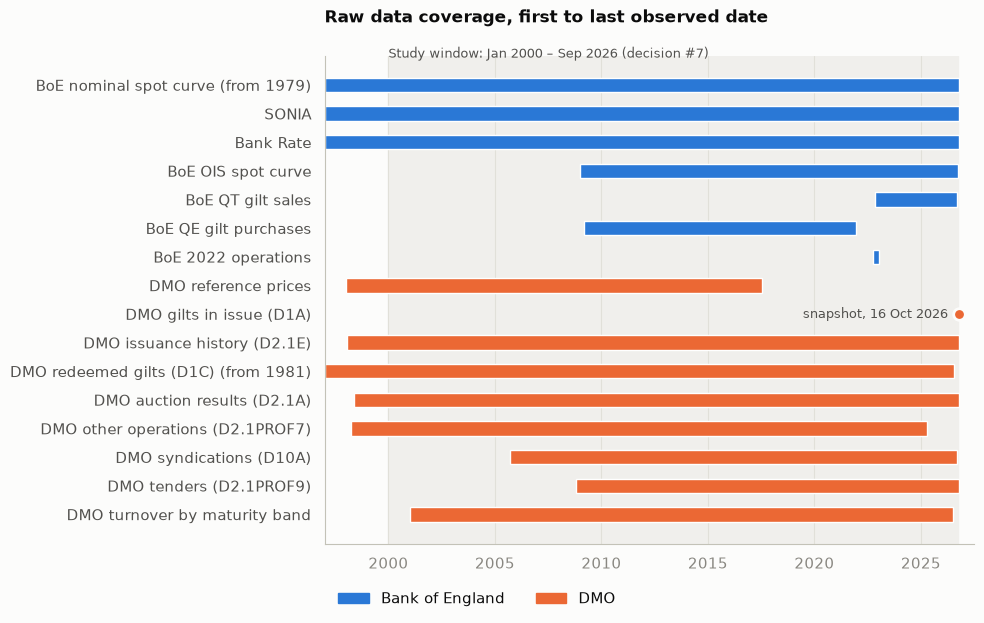

In [9]:
fam = (coverage.assign(first=pd.to_datetime(coverage["first"]), last=pd.to_datetime(coverage["last"]))
       .groupby("dataset").agg(first=("first", "min"), last=("last", "max"), n=("n", "sum"),
                               unit=("unit", "first"), files=("file", "count")).reset_index())
fam["publisher"] = np.where(fam["dataset"].str.contains("BoE|SONIA|Bank Rate"), "Bank of England", "DMO")
fam["key"] = fam["dataset"].str.extract(r"#(\d+)")[0].astype(int)
fam = fam.sort_values(["publisher", "key", "dataset"], ascending=[True, True, True]).reset_index(drop=True)
fam["label"] = fam["dataset"].str.replace(r"^#\S+\s", "", regex=True)
x0, x1 = pd.Timestamp("1997-01-01"), pd.Timestamp("2027-06-30")
fam.loc[fam["first"] < x0, "label"] += " (from " + fam["first"].dt.year.astype(str) + ")"   # range clipped by the axis
fam["snapshot"] = fam["first"] == fam["last"]                                                   # D1A: one date, drawn as a dot
colours = plotting.colour_map(["Bank of England", "DMO"])
win0, win1 = pd.Timestamp(config.STUDY_START), pd.Timestamp(config.STUDY_END)
window_label = "Study window: Jan 2000 – Sep 2026 (decision #7)"

# ---- static (seaborn theme + matplotlib bars)
fig_s, ax = plt.subplots(figsize=(10, 6.4))
ax.axvspan(win0, win1, color=plotting.NEUTRAL_BAND, zorder=0)
for i, r in fam.iterrows():
    if r["snapshot"]:
        ax.scatter(r["first"], i, s=70, color=colours[r["publisher"]], edgecolor=plotting.SURFACE, linewidth=2, zorder=3)
        ax.annotate("snapshot, " + r["first"].strftime("%d %b %Y"), (r["first"], i), xytext=(-8, 0),
                    textcoords="offset points", ha="right", va="center", fontsize=9, color=plotting.INK_SECONDARY)
    else:
        left = max(r["first"], x0)
        ax.barh(i, (r["last"] - left).days, left=left, height=0.5, color=colours[r["publisher"]], zorder=2)
ax.set_yticks(range(len(fam)), fam["label"]); ax.invert_yaxis()
ax.tick_params(axis="y", colors=plotting.INK_SECONDARY)
ax.set_xlim(x0, x1); ax.xaxis.set_major_locator(mdates.YearLocator(5)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", visible=False)
ax.set_title("Raw data coverage, first to last observed date", pad=24)
ax.text(win0, -0.85, window_label, color=plotting.INK_SECONDARY, fontsize=9, va="bottom")   # above the first row
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()]
ax.legend(handles, colours.keys(), loc="upper left", bbox_to_anchor=(0, -0.07), ncol=2)
fig_s.tight_layout()

# ---- interactive (Plotly)
fig_p = go.Figure()
fig_p.add_vrect(x0=win0, x1=win1, fillcolor=plotting.NEUTRAL_BAND, line_width=0, layer="below")
fig_p.add_annotation(x=win0, y=1.0, xref="x", yref="paper", yanchor="bottom", xanchor="left", showarrow=False,
                     text=window_label, font=dict(color=plotting.INK_SECONDARY, size=12))
hover = ("<b>%{y}</b><br>%{customdata[0]} → %{customdata[1]}<br>"
         "%{customdata[2]} %{customdata[3]} in %{customdata[4]} file(s)<extra></extra>")
for pub in colours:
    g = fam[(fam["publisher"] == pub) & ~fam["snapshot"]]
    cd = np.c_[g["first"].dt.strftime("%d %b %Y"), g["last"].dt.strftime("%d %b %Y"),
               g["n"].map("{:,}".format), g["unit"], g["files"]]
    fig_p.add_bar(y=g["label"], x=(g["last"] - g["first"].clip(lower=x0)).dt.days * 86_400_000,
                  base=g["first"].clip(lower=x0), orientation="h", name=pub, legendgroup=pub,
                  marker_color=colours[pub], width=0.5, customdata=cd, hovertemplate=hover)
    snap = fam[(fam["publisher"] == pub) & fam["snapshot"]]
    if len(snap):
        fig_p.add_scatter(y=snap["label"], x=snap["first"], mode="markers", legendgroup=pub, showlegend=False,
                          marker=dict(size=10, color=colours[pub], line=dict(width=2, color=plotting.SURFACE)),
                          customdata=np.c_[snap["first"].dt.strftime("%d %b %Y"), snap["n"].map("{:,}".format), snap["unit"]],
                          hovertemplate="<b>%{y}</b><br>snapshot as at %{customdata[0]}<br>%{customdata[1]} %{customdata[2]}<extra></extra>")
fig_p.update_layout(template="gilt_study", title="Raw data coverage, first to last observed date",
                    barmode="overlay", barcornerradius=4, height=560,
                    yaxis=dict(autorange="reversed", categoryorder="array", categoryarray=list(fam["label"]),
                               showgrid=False, tickfont=dict(color=plotting.INK_SECONDARY)),
                    xaxis=dict(type="date", range=[x0, x1], dtick="M60", tickformat="%Y"),
                    legend=dict(orientation="h", y=-0.1, x=0), margin=dict(t=90))

png, html = plotting.save_pair("data_coverage", fig_s, fig_p)
print("saved:", png.relative_to(paths.ROOT), "|", html.relative_to(paths.ROOT))
plt.show()

## 7. What this stage found, and where each finding goes

| Finding | Goes to |
|---|---|
| 47 raw files, checksums identical on Nithin's machine and here | `data/raw_manifest.csv`, SOURCES.md |
| OIS ends 30 Sep 2026; OIS long end from Jan 2016 (not Dec 2021) | SOURCES.md known issues; build spec §7 (control C) |
| Curve max maturity 25y to 2015, 40y from 2016; no missing business days | build spec §3, §5; Stage 2 counts affected auctions |
| D2.1A: no ISIN, offered amount or lowest price; "Index-Linked" spelling trap | SOURCES.md; Stage 3 panel builder (case-insensitive filter + test) |
| D2.1E issue date = auction settlement; ISIN join on priced rows is unique for all 915 conventional auctions; same-day direct issues to the DMO must be excluded; D2.1E truncates prices, so AAP/yield come from D2.1A | Stage 3 |
| Other operations include **taps** (supply) and end Apr 2025 | SOURCES.md; Stage 3 supply controls |
| Turnover bands add up to the DMO buckets | Stage 3 liquidity control |

## 8. Data changes in this stage (logged in `data/DATA.md`)

- **Created** `data/raw_manifest.csv` (checksums) and `data/processed_data/inventory/raw_coverage.csv` (the coverage table above).
- **Deleted** two hand-edited copies in `data/interim_data/` (with Nithin's permission). They duplicated raw files with renamed sheets and headers, and the production loaders now read the raw files directly.